 ML Lab 8
##### Name: Shlok Kasat
##### Section-Batch: A-A1
##### Roll No: 11

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import f1_score, precision_score, recall_score , ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('ai4i2020.csv')

In [3]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [13]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [8]:
df.shape

(10000, 14)

In [9]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [11]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [12]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [15]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [16]:
df["Machine failure"].value_counts(normalize=True)*100

,proportion
Machine failure,
0,96.61
1,3.39


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

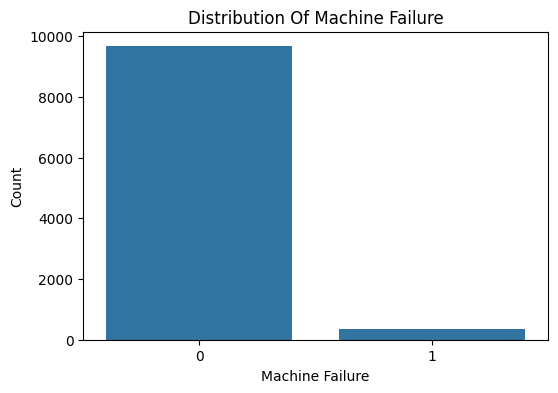

In [18]:
plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure",data=df)

plt.title("Distribution Of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

Algorithm

In [24]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

print(X.head())

  Type  Air temperature [K]  ...  Torque [Nm]  Tool wear [min]
0    M                298.1  ...         42.8                0
1    L                298.2  ...         46.3                3
2    L                298.1  ...         49.4                5
3    L                298.2  ...         39.5                7
4    L                298.2  ...         40.0                9

[5 rows x 6 columns]


In [25]:
y = df["Machine failure"]

In [26]:
print("Input Shape: ",X.shape)
print("Output Shape: ",y.shape)

Input Shape:  (10000, 6)
Output Shape:  (10000,)


In [36]:
categorical_features = ["Type"]

numeric_features = [
            "Air Temperature [K]",
             "Process Temperature [K]",
              "Rotational Speed [rpm]",
              "Torque [Nm]",
            "Tool wear [min]"
]

In [37]:
X_train, X_test , y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training Samples: ",X_train.shape[0])
print("Testing Samples: ",X_test.shape[0])

Training Samples:  8000
Testing Samples:  2000


In [38]:
preprocessor = ColumnTransformer(
  transformers=   [
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_feature)

    ]
)

Kernel-Linear

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [47]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [48]:
y_pred_linear = linear_svm.predict(X_test)

print(y_pred_linear[:10])

[0 0 0 0 0 0 0 0 0 0]


In [49]:
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=["No Failure", "Failure"]
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



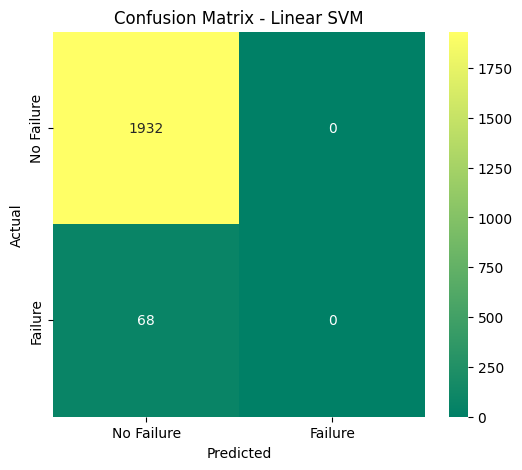

In [50]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [51]:
accuracy = accuracy_score(y_test, y_pred_linear)
precision = precision_score(y_test, y_pred_linear, zero_division=0)
recall = recall_score(y_test, y_pred_linear, zero_division=0)
f1 = f1_score(y_test, y_pred_linear, zero_division=0)

# Print results
print("Linear SVM Performance:")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

Linear SVM Performance:
Accuracy  : 0.9660
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000


## Karnel - RBF

In [52]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)

rbf_svm.fit(X_train, y_train)

y_pred_rbf = rbf_svm.predict(X_test)

In [53]:
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [54]:
y_pred_rbf = rbf_svm.predict(X_test)

print(y_pred_rbf[:10])

[0 0 0 0 0 0 0 0 0 0]


In [57]:
print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=["No Failure", "Failure"]
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



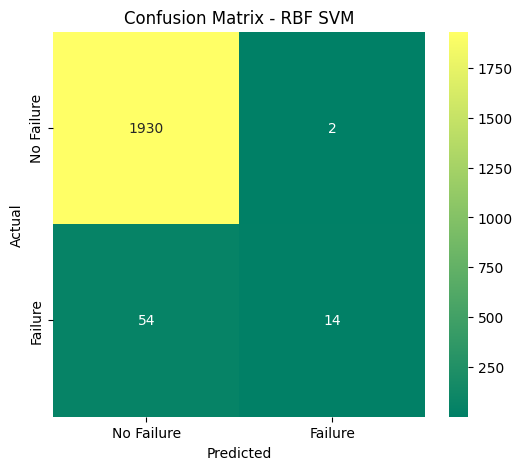

In [58]:
cm_linear = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.title("Confusion Matrix - RBF SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Kernel - Polynomial

In [61]:
poly_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="poly"))
    ]
)

poly_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='poly'))])

In [62]:
y_pred_poly = poly_svm.predict(X_test)

print(y_pred_poly[:10])

[0 0 0 0 0 0 0 0 0 0]


In [63]:
print(
    classification_report(
        y_test,
        y_pred_poly,
        target_names=["No Failure", "Failure"]
    )
)

              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



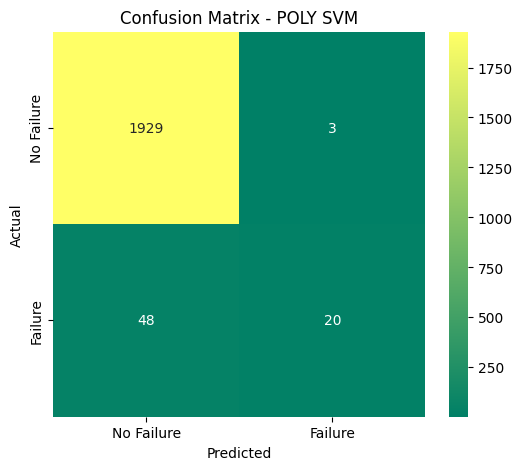

In [64]:
cm_linear = confusion_matrix(y_test, y_pred_poly)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.title("Confusion Matrix - POLY SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Kernal - Sigmoid

In [65]:
sigmoid_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="sigmoid"))
    ]
)

sigmoid_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='sigmoid'))])

In [66]:
y_pred_sigmoid = sigmoid_svm.predict(X_test)

print(y_pred_sigmoid[:10])

[0 1 0 0 0 0 0 0 0 0]


In [67]:
print(
    classification_report(
        y_test,
        y_pred_sigmoid,
        target_names=["No Failure", "Failure"]
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      0.97      0.97      1932
     Failure       0.15      0.13      0.14        68

    accuracy                           0.94      2000
   macro avg       0.56      0.55      0.56      2000
weighted avg       0.94      0.94      0.94      2000



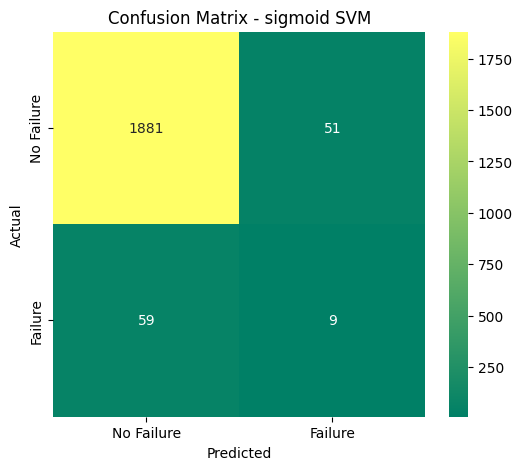

In [68]:
cm_linear = confusion_matrix(y_test, y_pred_sigmoid)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.title("Confusion Matrix - sigmoid SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [70]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


predictions = {
    "Linear": y_pred_linear,
    "RBF": y_pred_rbf,
    "Polynomial": y_pred_poly,
    "Sigmoid": y_pred_sigmoid
}


results = []

for kernel, y_pred in predictions.items():
    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison = pd.DataFrame(results)

print(comparison.round(4))

       Kernel  Accuracy  Precision  Recall  F1-Score
0      Linear    0.9660     0.0000  0.0000    0.0000
1         RBF    0.9720     0.8750  0.2059    0.3333
2  Polynomial    0.9745     0.8696  0.2941    0.4396
3     Sigmoid    0.9450     0.1500  0.1324    0.1406


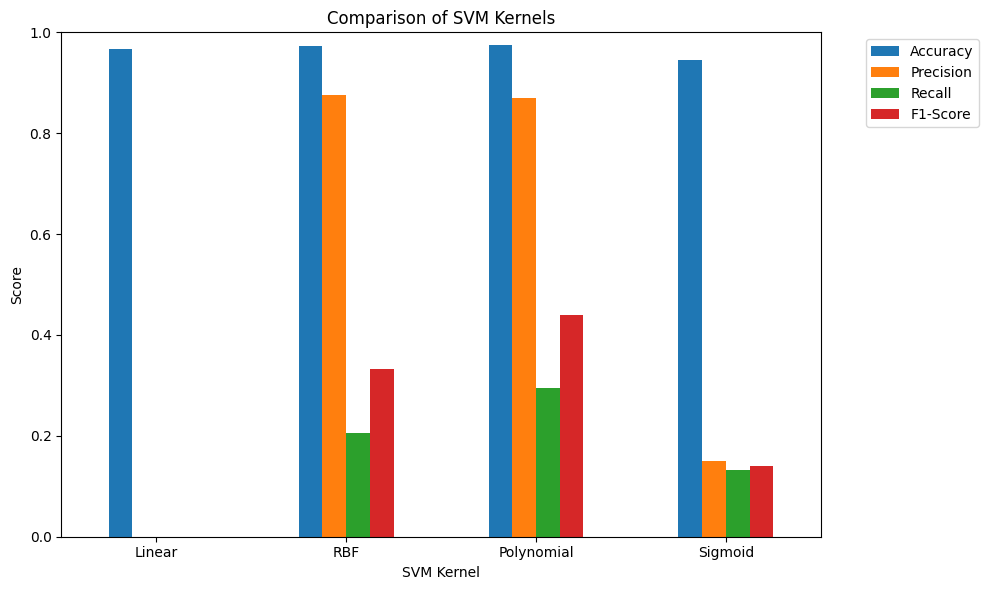

In [71]:
comparison_plot = comparison.set_index("Kernel")
comparison_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1),loc="upper left")
plt.tight_layout()
plt.show()

## Tunning

In [72]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC())
    ]
)

In [87]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__gamma": ["scale", 0.01, 0.1, 1],
        "classifier__C": [0.1, 1, 10, 100]
    }
]



In [88]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5 , scoring = "f1", n_jobs=-1, verbose=1)

In [89]:
grid_search.fit(X_train, y_train)
print("GridSearchCV complete")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearchCV complete


In [91]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [92]:
print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)


Best Cross-Validation F1 Score:
0.7080372186703207


In [93]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

In [94]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

print("Tuned SVM Results")
print(f"Accuracy  : {accuracy_tuned:.4f}")
print(f"Precision : {precision_tuned:.4f}")
print(f"Recall    : {recall_tuned:.4f}")
print(f"F1-score  : {f1_tuned:.4f}")

Tuned SVM Results
Accuracy  : 0.9800
Precision : 0.7593
Recall    : 0.6029
F1-score  : 0.6721
